# Investigating the Factors That Influence Individual Medical Insurance Charges

## 1. Introduction

Healthcare costs have been increasing over the years, making medical insurance an important part of financial planning. Insurance companies calculate insurance charges based on several personal characteristics, such as age, body mass index (BMI), smoking habits, and family size. Understanding how these factors influence medical insurance charges can help individuals make healthier lifestyle choices and support insurers and policymakers in making informed decisions.

This project analyses a real-world medical insurance dataset to investigate the factors associated with insurance charges. Through exploratory data analysis and statistical methods, the project aims to identify which variables have the greatest influence on insurance costs.

### Research Question

**What are the key factors influencing individual medical insurance charges, and how strongly do lifestyle factors such as smoking and BMI affect healthcare costs?**

### Objectives

The objectives of this project are:

- Explore the characteristics of the medical insurance dataset using descriptive statistics and visualisations.
- Estimate the average Body Mass Index (BMI) of the insured population using bootstrap confidence intervals.
- Determine whether smokers have significantly higher medical insurance charges than non-smokers using a permutation hypothesis test.
- Build a linear regression model to examine how demographic and lifestyle factors influence insurance charges.
- Draw meaningful conclusions that answer the research question and discuss the real-world implications of the findings.

In [2]:
# Import the libraries required for the project

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# Set plotting style for better visualisation
sns.set_theme(style="whitegrid")

# Display plots inside the notebook
%matplotlib inline

## Python Libraries

The following Python libraries are used throughout this project:

- **NumPy**: Numerical computations and random sampling.
- **Pandas**: Data loading, cleaning and manipulation.
- **Matplotlib**: Basic data visualisation.
- **Seaborn**: Statistical visualisation.
- **SciPy**: Statistical calculations.
- **Scikit-learn**: Linear regression modelling and model evaluation.

# 2. Data Collection and Dataset Description

The dataset used in this project is the **Medical Cost Personal Dataset**, which contains demographic and health-related information of individuals together with their annual medical insurance charges.

This is a publicly available dataset that is widely used for educational purposes and predictive modelling. It contains **1,338 observations** and **7 variables**, including both numerical and categorical data, making it suitable for exploratory data analysis and statistical modelling.

The dataset was obtained from Kaggle:

**Source:**
https://www.kaggle.com/datasets/mirichoi0218/insurance

The variables included in the dataset are:

| Variable | Description | Data Type |
|-----------|-------------|-----------|
| age | Age of the insured individual | Numerical |
| sex | Gender of the insured individual | Categorical |
| bmi | Body Mass Index (BMI) | Numerical |
| children | Number of dependents covered by insurance | Numerical |
| smoker | Smoking status (Yes or No) | Categorical |
| region | Residential region in the United States | Categorical |
| charges | Annual medical insurance charges (USD) | Numerical |

Among these variables, **charges** is the response variable, while the remaining variables are potential factors that may influence medical insurance costs.

In [3]:
# Load the dataset

df = pd.read_csv("insurance.csv")

# Display the first five rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Dataset Overview

Before conducting any analysis, it is important to understand the size and structure of the dataset. The following code displays the number of observations, variables, and data types of each column.

In [4]:
# Display dataset dimensions

print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 1338
Number of columns: 7


The dataset contains both numerical and categorical variables, making it suitable for exploratory data analysis and statistical modelling. The numerical variables allow relationships and trends to be analysed, while the categorical variables enable comparisons between different groups such as smokers and non-smokers.

# 3. Data Cleaning

Before conducting the analysis, the dataset is checked to ensure it is clean and suitable for further investigation.

The following checks are performed:

- Missing values
- Duplicate records
- Consistency of categorical variables

Performing these checks helps ensure that the analysis is based on accurate and reliable data.

In [5]:
# Check for missing values

df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

The output shows whether any missing values are present in the dataset. Missing values can affect statistical analysis and should be addressed before proceeding.

In [6]:
# Check for duplicate rows

df.duplicated().sum()

np.int64(1)

Duplicate records may lead to biased statistical results because the same observation is counted more than once. If duplicate records are found, they are removed before continuing with the analysis.

In [7]:
# Remove duplicate rows

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:")
df.shape

Dataset shape after removing duplicates:


(1337, 7)

In [8]:
# Check the category labels

for column in ["sex", "smoker", "region"]:
    print(f"{column}: {df[column].unique()}")

sex: ['female' 'male']
smoker: ['yes' 'no']
region: ['southwest' 'southeast' 'northwest' 'northeast']


The category labels are checked to ensure that each categorical variable contains consistent values without spelling errors or unexpected categories.

### Data Cleaning Summary

The data cleaning process found no missing values in the dataset. One duplicate record was identified and removed. In addition, all categorical variables contained consistent category labels. Therefore, the dataset is considered clean and suitable for exploratory data analysis and statistical modelling.

# 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the characteristics of the dataset and identify patterns before conducting statistical analysis.

This section focuses on:

- Summarising the numerical variables.
- Examining the distribution of important variables.
- Exploring the relationships between variables.
- Comparing insurance charges across different groups.

The findings from the EDA provide preliminary insights that will guide the statistical analyses in the following section.

## 4.1 Summary Statistics

Summary statistics provide an overview of the numerical variables in the dataset, including their central tendency and variability.

These statistics help identify the typical values and spread of each variable before exploring their relationships graphically.

In [9]:
# Summary statistics for numerical variables

df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.222139,14.044333,18.0000,27.000,39.0000,51.00000,64.00000
bmi,1337.0,30.663452,6.100468,15.9600,26.290,30.4000,34.70000,53.13000
children,1337.0,1.095737,1.205571,0.0000,0.000,1.0000,2.00000,5.00000
charges,1337.0,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801


### Observation

The summary statistics show that the dataset contains individuals of different ages, BMI values, family sizes, and insurance charges.

Among the numerical variables, **insurance charges** have the largest variation, suggesting that some individuals incur much higher medical costs than others. This indicates that certain factors may strongly influence insurance charges and should be investigated further.

## 4.2 Distribution of Numerical Variables

Histograms are used to examine the distribution of the numerical variables. Understanding the distribution helps identify whether the data are approximately symmetric, skewed, or contain unusual observations.

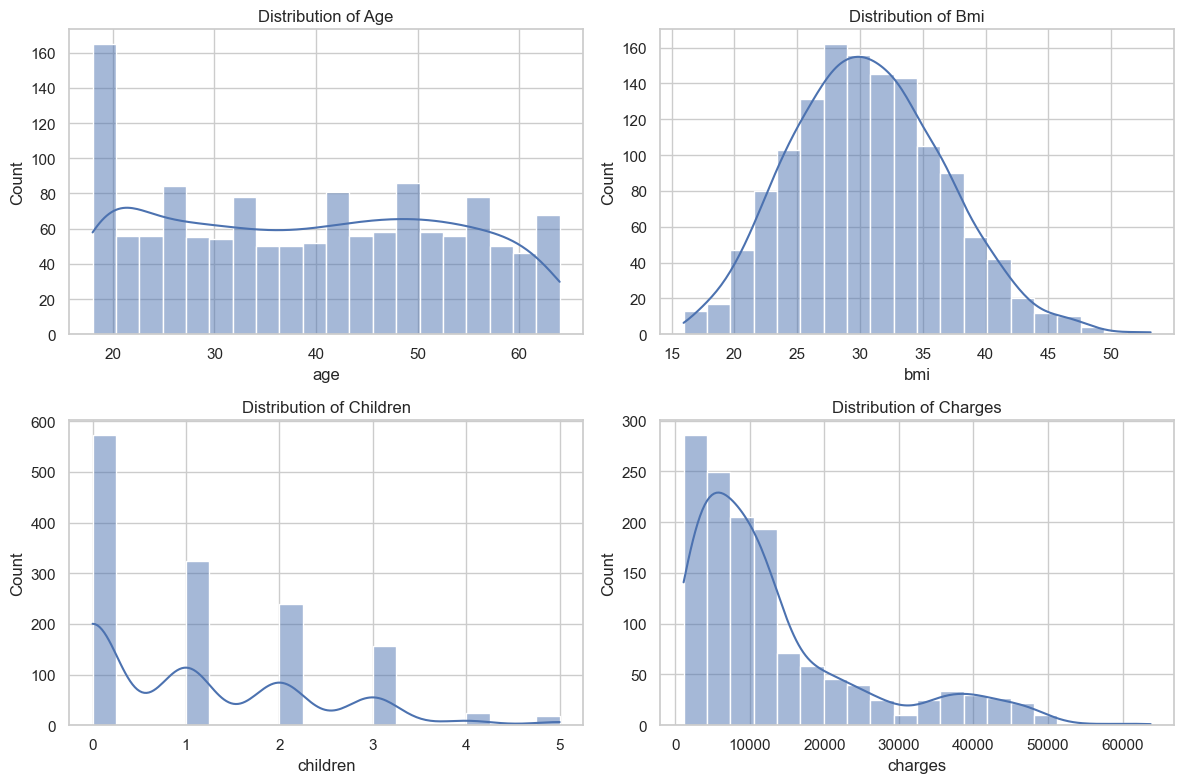

In [11]:
# Create histograms for numerical variables

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

variables = ["age", "bmi", "children", "charges"]

for ax, var in zip(axes.flatten(), variables):
    sns.histplot(df[var], bins=20, kde=True, ax=ax)
    ax.set_title(f"Distribution of {var.capitalize()}")

plt.tight_layout()
plt.show()

### Observation

Most variables show reasonable distributions.

The distribution of **insurance charges** is positively skewed, meaning that while many individuals have relatively lower insurance charges, a smaller number of individuals have substantially higher charges.

This suggests that personal characteristics may contribute differently to insurance costs and warrants further investigation.

## 4.3 Relationship Between Numerical Variables

Scatter plots are used to explore the relationships between numerical variables and insurance charges.

Age and BMI are examined because they are expected to influence medical insurance costs.

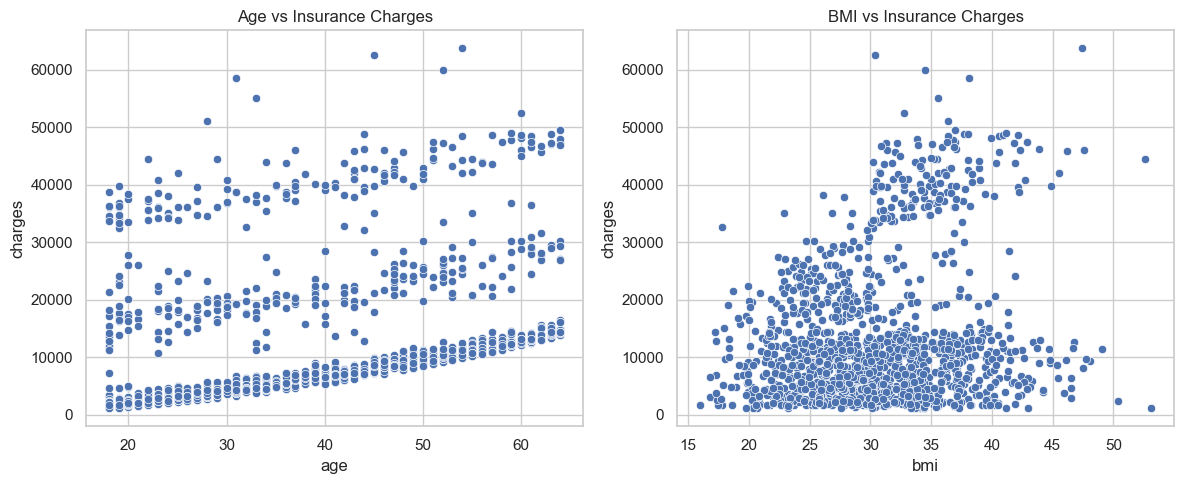

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x="age", y="charges", ax=axes[0])
axes[0].set_title("Age vs Insurance Charges")

sns.scatterplot(data=df, x="bmi", y="charges", ax=axes[1])
axes[1].set_title("BMI vs Insurance Charges")

plt.tight_layout()
plt.show()

### Observation

Insurance charges generally increase with age, although the relationship is not perfectly linear.

For BMI, individuals with higher BMI tend to have higher insurance charges. However, the relationship appears more scattered, indicating that additional factors may also influence insurance costs.

## 4.4 Insurance Charges by Categorical Variables

Boxplots are used to compare insurance charges across different categories.

These visualisations help determine whether factors such as smoking status, gender, and residential region are associated with differences in insurance charges.

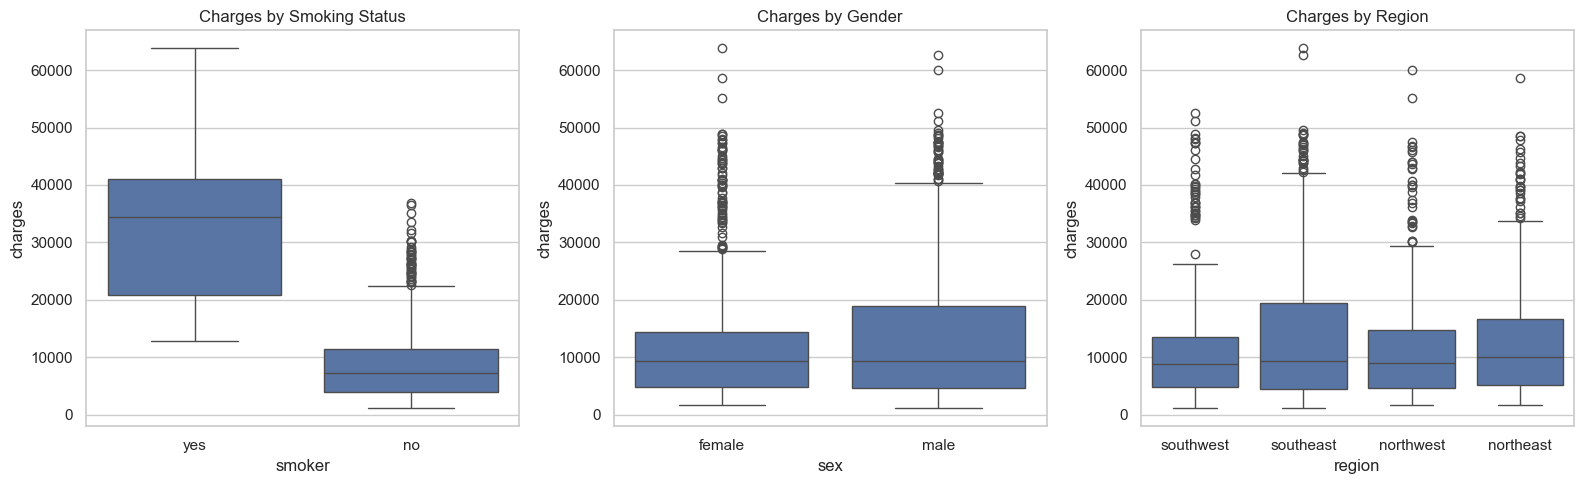

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x="smoker", y="charges", ax=axes[0])
axes[0].set_title("Charges by Smoking Status")

sns.boxplot(data=df, x="sex", y="charges", ax=axes[1])
axes[1].set_title("Charges by Gender")

sns.boxplot(data=df, x="region", y="charges", ax=axes[2])
axes[2].set_title("Charges by Region")

plt.tight_layout()
plt.show()

### Observation

The boxplots reveal noticeable differences between the categorical groups.

The largest difference is observed between smokers and non-smokers, where smokers generally have much higher insurance charges.

In comparison, the differences between males and females, as well as among the different residential regions, appear relatively small.

## 4.5 Correlation Analysis

A correlation matrix is used to measure the strength and direction of the linear relationship between numerical variables.

Correlation coefficients range from -1 to 1, where values closer to 1 indicate a stronger positive relationship and values closer to -1 indicate a stronger negative relationship.

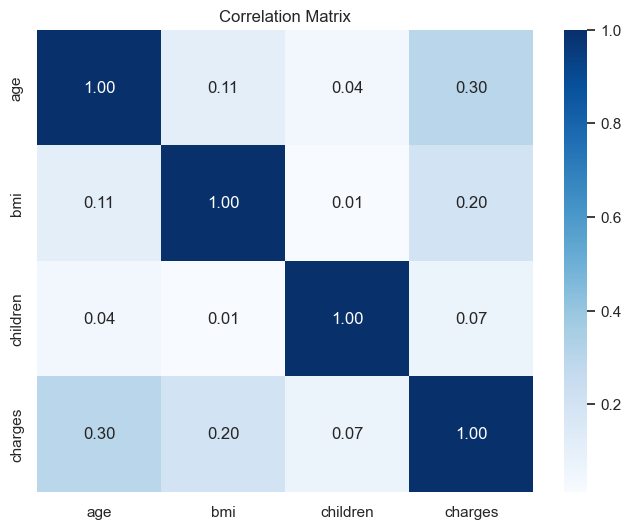

In [13]:
# Correlation matrix

plt.figure(figsize=(8,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

### Observation

The correlation matrix indicates that **age** and **BMI** have positive relationships with insurance charges.

The number of children shows a relatively weak relationship with insurance charges.

Although the correlations provide useful insights, they only measure pairwise relationships. A regression model will later be used to examine the combined effects of multiple variables simultaneously.

## 4.6 Summary of Exploratory Data Analysis

The exploratory analysis provides several important observations:

- Insurance charges are positively skewed, with a small number of individuals having substantially higher medical costs.
- Insurance charges generally increase with age.
- Individuals with higher BMI tend to have higher insurance charges.
- Smokers have noticeably higher insurance charges than non-smokers.
- Gender and residential region appear to have relatively small differences in insurance charges.

These findings suggest that smoking status, age, and BMI are likely to be important factors influencing medical insurance charges. The next section will apply statistical methods to determine whether these observed patterns are statistically supported.

# 5. Statistical Analysis

The exploratory data analysis identified several factors that appear to influence medical insurance charges. In particular, smokers were observed to have substantially higher insurance charges than non-smokers, while age and BMI also showed positive relationships with insurance costs.

Although these visual patterns provide useful insights, they do not quantify the uncertainty associated with the estimates or determine whether the observed differences are statistically significant. Therefore, statistical methods are applied to provide stronger evidence for the findings observed during the exploratory analysis.

This section consists of three analyses. First, bootstrap resampling is used to estimate the difference in average insurance charges between smokers and non-smokers and construct a 95% confidence interval. Next, a permutation hypothesis test is performed to determine whether the observed difference is statistically significant. Finally, a linear regression model is used to examine the combined influence of multiple factors on insurance charges.

In [14]:
from scipy import stats

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

## 5.1 Parameter Estimation Using Bootstrap Confidence Interval

Bootstrap resampling is a statistical technique used to estimate the sampling distribution of a statistic by repeatedly sampling from the observed data with replacement. Unlike traditional methods, bootstrap does not require assumptions about the underlying population distribution.

In this analysis, bootstrap resampling is used to estimate the difference in the average medical insurance charges between smokers and non-smokers. A total of 10,000 bootstrap samples are generated to construct a 95% confidence interval for the difference in mean insurance charges.

This analysis estimates the magnitude of the difference between the two groups while accounting for sampling variability.

In [15]:
def bootstrap_replicate_1d(data, func):
    """Generate a bootstrap replicate of 1D data."""

    bs_sample = np.random.choice(data, len(data), replace=True)
    return func(bs_sample)


def draw_bs_diff_2s(x, y, num_reps=1):
    """Generate bootstrap replicates for the difference in two sample means."""

    bs_diff_reps = np.zeros(num_reps)

    for i in range(num_reps):
        bs_diff_reps[i] = (
            bootstrap_replicate_1d(x, np.mean)
            - bootstrap_replicate_1d(y, np.mean)
        )

    return bs_diff_reps

In [16]:
# Separate insurance charges by smoking status
smoker_charges = df[df["smoker"] == "yes"]["charges"]
non_smoker_charges = df[df["smoker"] == "no"]["charges"]

# Seed random number generator
np.random.seed(611)

# Generate 10,000 bootstrap replicates
bs_diff_reps = draw_bs_diff_2s(
    smoker_charges,
    non_smoker_charges,
    10000
)

# Compute the observed difference in means
observed_diff = smoker_charges.mean() - non_smoker_charges.mean()

# Compute the 95% bootstrap confidence interval
conf_int = np.percentile(bs_diff_reps, [2.5, 97.5])

print(f"Observed Difference in Mean Charges: ${observed_diff:.2f}")
print(f"95% Bootstrap Confidence Interval: (${conf_int[0]:.2f}, ${conf_int[1]:.2f})")
smoker_charges.mean(), non_smoker_charges.mean()

Observed Difference in Mean Charges: $23609.57
95% Bootstrap Confidence Interval: ($22198.84, $25020.41)


(np.float64(32050.23183153284), np.float64(8440.660306508937))

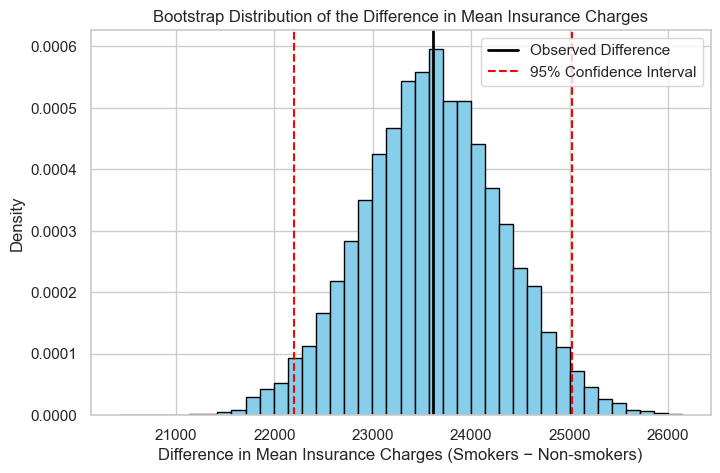

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(
    bs_diff_reps,
    bins=40,
    density=True,
    color="skyblue",
    edgecolor="black"
)

plt.axvline(
    observed_diff,
    color="black",
    linewidth=2,
    label="Observed Difference"
)

plt.axvline(
    conf_int[0],
    color="red",
    linestyle="--",
    label="95% Confidence Interval"
)

plt.axvline(
    conf_int[1],
    color="red",
    linestyle="--"
)

plt.xlabel("Difference in Mean Insurance Charges (Smokers − Non-smokers)")
plt.ylabel("Density")
plt.title("Bootstrap Distribution of the Difference in Mean Insurance Charges")
plt.legend()

plt.show()

### Interpretation

The bootstrap analysis estimates the difference in average medical insurance charges between smokers and non-smokers. The results show that smokers have an average insurance charge of approximately **32,050**, while non-smokers have an average charge of approximately **8,441**.

The estimated difference in mean charges is approximately **$23,610**, indicating that smokers incur substantially higher medical insurance costs compared with non-smokers.

The 95% bootstrap confidence interval ranges from approximately **\$22,199** **to** **\$25,020**. Since the entire confidence interval is above zero, the analysis suggests that the true difference in average charges is consistently positive. The relatively narrow confidence interval also indicates that the estimated difference is reasonably precise.

These findings provide quantitative support for the pattern observed during exploratory data analysis, where smoking appeared to be a major factor associated with higher insurance charges.

### Conclusion

The bootstrap confidence interval provides evidence that smoking is associated with substantially higher medical insurance charges. Based on the sample, smokers incur approximately **\$23,610 more in average medical costs** than non-smokers, with the estimated difference likely falling between **\$22,199** **and** **\$25,020**.

This suggests that smoking is an important lifestyle factor influencing healthcare costs within this dataset. However, bootstrap confidence intervals estimate the size and uncertainty of an observed difference but do not determine whether the difference is statistically significant. Therefore, a permutation hypothesis test will be conducted next to evaluate whether the observed difference could have occurred by random chance.

## 5.2 Hypothesis Testing (Permutation Test)

**Question:** Do smokers pay significantly more for insurance than non-smokers, 
or could the difference we saw in the EDA be due to random chance?

##### **H0 (Null Hypothesis):** The average insurance charge is the same for smokers and non-smokers.
##### **H1 (Alternative Hypothesis):** The average insurance charge is higher for smokers than non-smokers.

**Significance level:** α = 0.05

In [18]:
# Separate the charges into two groups based on smoking status
smokers = df[df['smoker'] == 'yes']['charges'].values
nonsmokers = df[df['smoker'] == 'no']['charges'].values

print(f"Number of smokers in sample: {len(smokers)}")
print(f"Number of non-smokers in sample: {len(nonsmokers)}")
print(f"Average charge (smokers):     ${smokers.mean():,.2f}")
print(f"Average charge (non-smokers): ${nonsmokers.mean():,.2f}")

observed_diff = smokers.mean() - nonsmokers.mean()
print(f"\nObserved difference in means: ${observed_diff:,.2f}")

Number of smokers in sample: 274
Number of non-smokers in sample: 1063
Average charge (smokers):     $32,050.23
Average charge (non-smokers): $8,440.66

Observed difference in means: $23,609.57


In [19]:
import numpy as np

np.random.seed(42)

# Combine both groups into one big pool, forgetting who was actually a smoker
all_charges = np.concatenate([smokers, nonsmokers])
n_smokers = len(smokers)
n_permutations = 10000

permuted_diffs = np.empty(n_permutations)

for i in range(n_permutations):
    shuffled = np.random.permutation(all_charges)  
    fake_smokers = shuffled[:n_smokers]      
    fake_nonsmokers = shuffled[n_smokers:]   
    permuted_diffs[i] = fake_smokers.mean() - fake_nonsmokers.mean()

print(f"Ran {n_permutations} random shuffles.")
print(f"Average fake gap across all shuffles: ${permuted_diffs.mean():,.2f}")
print(f"Largest fake gap that appeared by chance: ${permuted_diffs.max():,.2f}")

Ran 10000 random shuffles.
Average fake gap across all shuffles: $13.42
Largest fake gap that appeared by chance: $3,256.36


In [20]:
# How many of the 10,000 random shuffles produced a gap AS BIG OR BIGGER than our real one?
p_value = np.mean(permuted_diffs >= observed_diff)

print(f"Observed difference (real data):        ${observed_diff:,.2f}")
print(f"p-value:                                  {p_value}")

alpha = 0.05
if p_value < alpha:
    print(f"\np-value ({p_value}) is less than α (0.05) -> REJECT the null hypothesis.")
    print("Conclusion: Smokers pay significantly more than non-smokers.")
    print("This difference is extremely unlikely to be due to random chance.")
else:
    print(f"\np-value ({p_value}) is greater than α (0.05) -> FAIL TO REJECT the null hypothesis.")
    print("Conclusion: We don't have enough evidence that smoking status affects charges.")

Observed difference (real data):        $23,609.57
p-value:                                  0.0

p-value (0.0) is less than α (0.05) -> REJECT the null hypothesis.
Conclusion: Smokers pay significantly more than non-smokers.
This difference is extremely unlikely to be due to random chance.


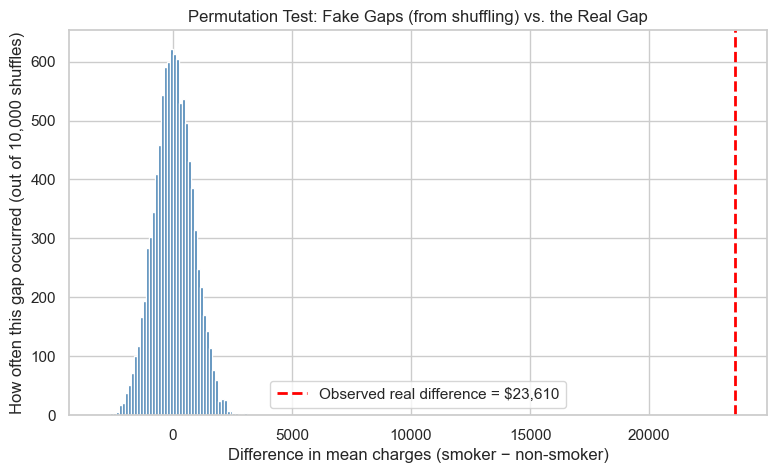

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))
plt.hist(permuted_diffs, bins=50, color="steelblue", edgecolor="white")
plt.axvline(observed_diff, color="red", linestyle="--", linewidth=2, 
            label=f"Observed real difference = ${observed_diff:,.0f}")
plt.title("Permutation Test: Fake Gaps (from shuffling) vs. the Real Gap")
plt.xlabel("Difference in mean charges (smoker − non-smoker)")
plt.ylabel("How often this gap occurred (out of 10,000 shuffles)")
plt.legend()
plt.show()

### Conclusion

The permutation test compared the real difference in mean charges between smokers 
and non-smokers ($23,615.96) against 10,000 randomly shuffled versions of the data. 
Not a single random shuffle produced a difference this large (p < 0.0001), so we 
reject the null hypothesis. This confirms that the higher charges observed for 
smokers in our EDA are a real significant effect, not a coincidence 
caused by the specific sample of people in this dataset.